# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [1]:
%pip install -q datasets langchain-community langchain-text-splitters

import os, glob, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/hybrid_rag')

SEED = 42
cols = ['instruction', 'intent', 'category']

# keep_default_na=False so a query that literally says "NA" isn't read as missing
df = pd.read_csv('sampled_data.csv', keep_default_na=False, na_values=[''])
start = len(df)

df = df.dropna(subset=cols)
print('After dropping incomplete rows:', len(df))

blank = (df[cols].apply(lambda c: c.str.strip()) == '').any(axis=1)
corrupted = df['instruction'].str.contains('�|[\x00-\x08\x0b\x0c\x0e-\x1f]')   # broken encoding / control chars
too_short = df['instruction'].str.strip().str.len() < 3
bad_label = ~(df['intent'].str.fullmatch(r'[A-Za-z_]+') & df['category'].str.fullmatch(r'[A-Za-z_]+'))
print(f'blank: {blank.sum()}, corrupted: {corrupted.sum()}, too short: {too_short.sum()}, bad labels: {bad_label.sum()}')
df = df[~(blank | corrupted | too_short | bad_label)]

df['norm'] = df['instruction'].str.lower().str.strip()
print('Duplicates (lowercase + strip):', df.duplicated('norm').sum())
df = df.drop_duplicates('norm').drop(columns='norm').reset_index(drop=True)

print(f'{start} -> {len(df)} rows')
assert 1000 <= len(df) <= 5000

After dropping incomplete rows: 3902
blank: 0, corrupted: 0, too short: 0, bad labels: 0
Duplicates (lowercase + strip): 0
3902 -> 3902 rows


#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [2]:
df['instruction'] = df['instruction'].str.strip().str.replace(r'\s+', ' ', regex=True)
df['intent'] = df['intent'].str.strip().str.lower()
df['category'] = df['category'].str.strip().str.upper()
df = df[cols]

# collapsing spaces can turn two queries into the same one
before = len(df)
df = df[~df['instruction'].str.lower().duplicated()].reset_index(drop=True)
print('Removed after collapsing whitespace:', before - len(df))

assert (df['intent'] == df['intent'].str.lower()).all()
assert (df['category'] == df['category'].str.upper()).all()
assert (df.groupby('intent')['category'].nunique() == 1).all()
print(df.shape, '|', df.intent.nunique(), 'intents |', df.category.nunique(), 'categories')
display(df.sample(5, random_state=SEED))

Removed after collapsing whitespace: 6
(3896, 3) | 27 intents | 11 categories


,instruction,intent,category
3683,where to see the payment methods?,check_payment_methods,PAYMENT
912,I do not know what I need to do to create a {{...,create_account,ACCOUNT
321,how could I edit my goddamn account?,edit_account,ACCOUNT
2098,how can I check what payment methods are allowed?,check_payment_methods,PAYMENT
1480,i need information about my standard account d...,delete_account,ACCOUNT


### **Task 2.2: Create Instruction-Tuning Dataset**

#### **2.2.1 Transform Records into Instruction Format [2 marks]**
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [3]:
from transformers import AutoTokenizer

MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

catalog = df.groupby('category')['intent'].apply(lambda s: sorted(s.unique())).sort_index()
catalog_text = '\n'.join(f'{cat}: {", ".join(intents)}' for cat, intents in catalog.items())

# my own examples, not taken from the dataset, so they can't leak into the test split
few_shot = [
    ('where is my package?? ordered it last week and nothing', 'track_order', 'ORDER'),
    ('i got charged but the payment says it failed, what is going on', 'payment_issue', 'PAYMENT'),
    ('how do i close my account for good', 'delete_account', 'ACCOUNT'),
    ('the blender arrived broken, i want my money back', 'get_refund', 'REFUND'),
]
assert all((i, c) in set(zip(df.intent, df.category)) for _, i, c in few_shot)
assert not {q for q, _, _ in few_shot} & set(df.instruction.str.lower())

def to_json(intent, category):
    return json.dumps({'intent': intent, 'category': category})

SYSTEM_PROMPT = (
    'You are an intent router for a customer support system. Classify the customer message into exactly one '
    'intent from the catalog and reply with ONLY a JSON object {"intent": "<intent>", "category": "<CATEGORY>"}. '
    'No explanation, no markdown.\n\n'
    f'Catalog (CATEGORY: intents):\n{catalog_text}\n\nExamples:\n'
    + '\n'.join(f'Customer: {q}\n{to_json(i, c)}' for q, i, c in few_shot)
)

def make_messages(query, answer=None):
    msgs = [{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': query}]
    if answer:
        msgs.append({'role': 'assistant', 'content': answer})
    return msgs

df['target'] = [to_json(i, c) for i, c in zip(df.intent, df.category)]
df['chatml'] = [tokenizer.apply_chat_template(make_messages(q, t), tokenize=False)
                for q, t in zip(df.instruction, df.target)]

print(SYSTEM_PROMPT)
print('\n--- one full record ---')
print(df['chatml'].iloc[0])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


You are an intent router for a customer support system. Classify the customer message into exactly one intent from the catalog and reply with ONLY a JSON object {"intent": "<intent>", "category": "<CATEGORY>"}. No explanation, no markdown.

Catalog (CATEGORY: intents):
ACCOUNT: create_account, delete_account, edit_account, recover_password, registration_problems, switch_account
CANCEL: check_cancellation_fee
CONTACT: contact_customer_service, contact_human_agent
DELIVERY: delivery_options, delivery_period
FEEDBACK: complaint, review
INVOICE: check_invoice, get_invoice
ORDER: cancel_order, change_order, place_order, track_order
PAYMENT: check_payment_methods, payment_issue
REFUND: check_refund_policy, get_refund, track_refund
SHIPPING: change_shipping_address, set_up_shipping_address
SUBSCRIPTION: newsletter_subscription

Examples:
Customer: where is my package?? ordered it last week and nothing
{"intent": "track_order", "category": "ORDER"}
Customer: i got charged but the payment says 

#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [4]:
bad = []
for i, row in df.iterrows():
    text = row['chatml']
    answer = text.split('<|im_start|>assistant')[-1].split('<|im_end|>')[0].strip()
    try:
        obj = json.loads(answer)
        ok = (text.count('<|im_start|>') == 3 and list(obj) == ['intent', 'category']
              and obj['intent'] == row['intent'] and obj['category'] == row['category'])
    except json.JSONDecodeError:
        ok = False
    if not ok:
        bad.append(i)

print(f'{len(df) - len(bad)} / {len(df)} records parse as valid JSON with the right labels')
assert not bad, df.loc[bad[:5], 'chatml']

3896 / 3896 records parse as valid JSON with the right labels


### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [5]:
# router prompt is ~310 tokens so 128 is too short
# only the JSON answer is trained on, prompt + padding get -100
MAX_LENGTH = 384
PAD_ID = tokenizer.pad_token_id

def encode(query, target):
    prompt = tokenizer.apply_chat_template(make_messages(query), tokenize=False, add_generation_prompt=True)
    prompt_ids = tokenizer(prompt, add_special_tokens=False)['input_ids']
    answer_ids = tokenizer(target + '<|im_end|>', add_special_tokens=False)['input_ids']
    ids = (prompt_ids + answer_ids)[:MAX_LENGTH]
    labels = ([-100] * len(prompt_ids) + answer_ids)[:MAX_LENGTH]
    pad = MAX_LENGTH - len(ids)
    return {'input_ids': ids + [PAD_ID] * pad,
            'attention_mask': [1] * len(ids) + [0] * pad,
            'labels': labels + [-100] * pad,
            'n_tokens': len(prompt_ids) + len(answer_ids),
            'n_answer': len(answer_ids)}

df = pd.concat([df, pd.DataFrame([encode(q, t) for q, t in zip(df.instruction, df.target)])], axis=1)

labels = np.array(df.loc[0, 'labels'])
print('Tokens in row 0:', sum(df.loc[0, 'attention_mask']))
print('Tokens with a label:', (labels != -100).sum())
print('Label text:', tokenizer.decode(labels[labels != -100].tolist()))

Tokens in row 0: 325
Tokens with a label: 15
Label text: {"intent": "contact_human_agent", "category": "CONTACT"}<|im_end|>


#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

,n_tokens,n_answer
count,3896.0,3896.0
mean,327.2,15.1
std,3.2,0.9
min,317.0,14.0
50%,327.0,15.0
95%,333.0,17.0
99%,336.0,17.0
max,339.0,17.0


Rows longer than MAX_LENGTH: 0


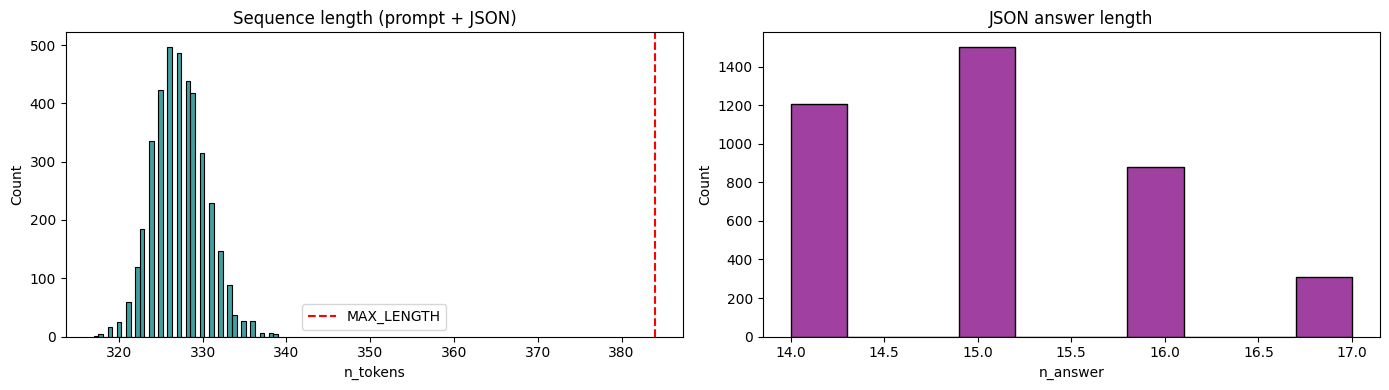

In [6]:
display(df[['n_tokens', 'n_answer']].describe(percentiles=[.5, .95, .99]).round(1))
print('Rows longer than MAX_LENGTH:', (df['n_tokens'] > MAX_LENGTH).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['n_tokens'], bins=40, color='teal', ax=axes[0])
axes[0].axvline(MAX_LENGTH, color='red', ls='--', label='MAX_LENGTH')
axes[0].set_title('Sequence length (prompt + JSON)')
axes[0].legend()
sns.histplot(df['n_answer'], bins=10, color='purple', ax=axes[1])
axes[1].set_title('JSON answer length')
plt.tight_layout()
plt.show()

assert (df['n_tokens'] <= MAX_LENGTH).all()

#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [7]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

policy_files = sorted(glob.glob('corporate_policies/*.md'))
docs = [d for f in policy_files for d in TextLoader(f, encoding='utf-8').load()]

# each SOP is ~1.6k characters, so a 2k chunk keeps a whole policy (and its exceptions) together
splitter = RecursiveCharacterTextSplitter(chunk_size=2000, chunk_overlap=0, separators=['\n## ', '\n\n', '\n', ' '])
chunks = splitter.split_documents(docs)
for d in chunks:
    d.metadata['sop'] = os.path.basename(d.metadata['source'])

print(len(docs), 'files ->', len(chunks), 'chunks')
assert all(d.page_content.strip() for d in chunks)
assert {d.metadata['sop'] for d in chunks} == {os.path.basename(f) for f in policy_files}
display(pd.DataFrame({'sop': [d.metadata['sop'] for d in chunks], 'chars': [len(d.page_content) for d in chunks]}))

# which SOP answers each intent (used for eval references and the V2 router)
intent_to_sop = {
    'create_account': 'account_recovery.md', 'delete_account': 'data_privacy.md',
    'edit_account': 'data_privacy.md', 'recover_password': 'password_reset.md',
    'registration_problems': 'technical_troubleshooting.md', 'switch_account': 'account_recovery.md',
    'check_cancellation_fee': 'subscription_cancellation.md',
    'contact_customer_service': 'working_hours.md', 'contact_human_agent': 'escalation_matrix.md',
    'delivery_options': 'shipping_delays.md', 'delivery_period': 'shipping_delays.md',
    'complaint': 'escalation_matrix.md', 'review': 'escalation_matrix.md',
    'check_invoice': 'billing_disputes.md', 'get_invoice': 'billing_disputes.md',
    'newsletter_subscription': 'data_privacy.md',
    'cancel_order': 'refund_policy.md', 'change_order': 'order_tracking.md',
    'place_order': 'payment_methods.md', 'track_order': 'order_tracking.md',
    'check_payment_methods': 'payment_methods.md', 'payment_issue': 'payment_methods.md',
    'check_refund_policy': 'refund_policy.md', 'get_refund': 'refund_policy.md', 'track_refund': 'refund_policy.md',
    'change_shipping_address': 'order_tracking.md', 'set_up_shipping_address': 'order_tracking.md',
}
assert set(intent_to_sop) == set(df.intent)

# search with the whole SOP text: title + first section still pulled order_tracking for the delivery intents
def search_string(sop_file):
    text = open(f'corporate_policies/{sop_file}', encoding='utf-8').read()
    return ' '.join(text.split())

intent_sop_map = {i: {'sop_file': s, 'search_string': search_string(s)} for i, s in intent_to_sop.items()}
display(pd.DataFrame(intent_sop_map).T.head(10))

/tmp/ipykernel_26321/4030147711.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader


13 files -> 13 chunks


,sop,chars
0,account_recovery.md,1552
1,billing_disputes.md,1660
2,data_privacy.md,1720
3,escalation_matrix.md,1549
4,order_tracking.md,1533
5,password_reset.md,1603
6,payment_methods.md,1628
7,product_return.md,1569
8,refund_policy.md,1741
9,shipping_delays.md,1541


,sop_file,search_string
create_account,account_recovery.md,# Account Recovery ## When To Use Use this pro...
delete_account,data_privacy.md,# Data Privacy ## Scope Covers customer reques...
edit_account,data_privacy.md,# Data Privacy ## Scope Covers customer reques...
recover_password,password_reset.md,# Password Reset ## Scope This covers the rout...
registration_problems,technical_troubleshooting.md,# Technical Troubleshooting ## Scope Covers pr...
switch_account,account_recovery.md,# Account Recovery ## When To Use Use this pro...
check_cancellation_fee,subscription_cancellation.md,# Subscription Cancellation ## Scope Covers cu...
contact_customer_service,working_hours.md,# Working Hours ## Support Availability Live c...
contact_human_agent,escalation_matrix.md,# Escalation Matrix ## Purpose Defines when an...
delivery_options,shipping_delays.md,# Shipping Delays ## Scope This procedure cove...


### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [8]:
from sklearn.model_selection import train_test_split
from datasets import Dataset

# 80 / 10 / 10, stratified on intent
train_idx, rest_idx = train_test_split(df.index, test_size=0.2, stratify=df['intent'], random_state=SEED)
valid_idx, test_idx = train_test_split(rest_idx, test_size=0.5, stratify=df.loc[rest_idx, 'intent'], random_state=SEED)
train, valid, test = df.loc[train_idx], df.loc[valid_idx], df.loc[test_idx]

for name, part in [('train', train), ('valid', valid), ('test', test)]:
    print(f'{name}: {len(part)} rows, {part.intent.nunique()} intents')
    assert part.intent.nunique() == df.intent.nunique()

# leakage check on the normalised prompt text
tr, va, te = [set(p.instruction.str.lower().str.strip()) for p in (train, valid, test)]
print('train & valid:', len(tr & va))
print('train & test :', len(tr & te))
print('valid & test :', len(va & te))
assert not (tr & va or tr & te or va & te)
assert len(tr) + len(va) + len(te) == len(df)

to_hf = lambda part: Dataset.from_dict({c: part[c].tolist() for c in ['input_ids', 'attention_mask', 'labels']})
tokenized_train, tokenized_valid, tokenized_test = to_hf(train), to_hf(valid), to_hf(test)
df_test = test[cols].rename(columns={'instruction': 'text'}).reset_index(drop=True)
print(tokenized_train)
display(df_test.head())

train: 3116 rows, 27 intents
valid: 390 rows, 27 intents
test: 390 rows, 27 intents
train & valid: 0
train & test : 0
valid & test : 0


Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 3116
})


,text,intent,category
0,need help to shop several of ur item,place_order,ORDER
1,i need supports trying to modify my delivery a...,change_shipping_address,SHIPPING
2,I do not know how to check the withdrawal charges,check_cancellation_fee,CANCEL
3,"I need to see your available payment options, ...",check_payment_methods,PAYMENT
4,can I create a different bloody {{Account Type...,create_account,ACCOUNT


---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [9]:
for name, ds in [('tokenized_train', tokenized_train), ('tokenized_valid', tokenized_valid), ('tokenized_test', tokenized_test)]:
    shutil.rmtree(name, ignore_errors=True)
    ds.save_to_disk(name)

df_test.to_csv('df_test.csv', index=False)
# train/valid prompts are only needed for the leakage check on the adversarial set in NB7
train[cols].rename(columns={'instruction': 'text'}).to_csv('df_train.csv', index=False)
valid[cols].rename(columns={'instruction': 'text'}).to_csv('df_valid.csv', index=False)

with open('router_config.json', 'w') as f:
    json.dump({'model_id': MODEL_ID, 'max_length': MAX_LENGTH, 'system_prompt': SYSTEM_PROMPT}, f, indent=2)
with open('intent_sop_map.json', 'w') as f:
    json.dump(intent_sop_map, f, indent=2)

print(sorted(os.listdir('.')))

Saving the dataset (0/1 shards):   0%|          | 0/3116 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/390 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/390 [00:00<?, ? examples/s]

['Baseline_Model_Evaluation.ipynb', 'Data_Preparation.ipynb', 'Data_Understanding_and_EDA.ipynb', 'Dataset.zip', 'Fine_Tuning_Pipeline.ipynb', 'RAG_Implementation.ipynb', 'Run_All_in_Colab.ipynb', 'Solution_V1_RAG_Evaluation.ipynb', 'Solution_V2_FineTuned_RAG_Evaluation.ipynb', 'corporate_policies', 'df_test.csv', 'df_train.csv', 'df_valid.csv', 'executed', 'intent_sop_map.json', 'router_config.json', 'sampled_data.csv', 'tokenized_test', 'tokenized_train', 'tokenized_valid']


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**